In [101]:
# Step 1. Import Libraries

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import pearsonr

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

In [102]:
# Step 2. Load Cleaned Dataset

PROJECT_ROOT = Path.cwd().parent
DATA_PROCESSED = PROJECT_ROOT / "data_processed"
OUTPUTS = PROJECT_ROOT / "outputs"

OUTPUTS.mkdir(exist_ok=True)

df = pd.read_csv(DATA_PROCESSED / "stroke_risk_panel_clean.csv")

print("Shape:", df.shape)
df.head()

Shape: (44, 7)


,PHU,Year,stroke_hosp_rate,smoking_rate,no_pa_minutes_rate,low_fv_rate,heavy_drinking_rate
0,Algoma Public Health,2016,127.8,26.2,19.0,73.2,55.1
1,Algoma Public Health,2017,131.1,26.2,19.0,73.2,55.1
2,Chatham-Kent Public Health,2016,146.7,19.0,20.6,72.7,49.5
3,Chatham-Kent Public Health,2017,139.0,19.0,20.6,72.7,49.5
4,City of Hamilton Public Health Services,2016,138.5,15.3,17.3,75.3,43.9


In [103]:
# Step 3. Quick Dataset check

print(df.info())
print("\nYears:", sorted(df["Year"].unique()))
print("Unique PHUs:", df["PHU"].nunique())
print("\nMissing values:")
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44 entries, 0 to 43
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   PHU                  44 non-null     object 
 1   Year                 44 non-null     int64  
 2   stroke_hosp_rate     44 non-null     float64
 3   smoking_rate         44 non-null     float64
 4   no_pa_minutes_rate   44 non-null     float64
 5   low_fv_rate          44 non-null     float64
 6   heavy_drinking_rate  44 non-null     float64
dtypes: float64(5), int64(1), object(1)
memory usage: 2.5+ KB
None

Years: [np.int64(2016), np.int64(2017)]
Unique PHUs: 22

Missing values:
PHU                    0
Year                   0
stroke_hosp_rate       0
smoking_rate           0
no_pa_minutes_rate     0
low_fv_rate            0
heavy_drinking_rate    0
dtype: int64


In [104]:
# Step 4. Define target and predictors

target = "stroke_hosp_rate"

risk_cols = [
    "smoking_rate",
    "no_pa_minutes_rate",
    "low_fv_rate",
    "heavy_drinking_rate"
]

df_model = df[["PHU", "Year", target] + risk_cols].copy()
df_model.head()

,PHU,Year,stroke_hosp_rate,smoking_rate,no_pa_minutes_rate,low_fv_rate,heavy_drinking_rate
0,Algoma Public Health,2016,127.8,26.2,19.0,73.2,55.1
1,Algoma Public Health,2017,131.1,26.2,19.0,73.2,55.1
2,Chatham-Kent Public Health,2016,146.7,19.0,20.6,72.7,49.5
3,Chatham-Kent Public Health,2017,139.0,19.0,20.6,72.7,49.5
4,City of Hamilton Public Health Services,2016,138.5,15.3,17.3,75.3,43.9


In [105]:
# Step 5. Correlation matrix

corr_matrix = df_model[[target] + risk_cols].corr()
corr_matrix

,stroke_hosp_rate,smoking_rate,no_pa_minutes_rate,low_fv_rate,heavy_drinking_rate
stroke_hosp_rate,1.000000,0.614514,-0.334948,0.192349,0.425241
smoking_rate,0.614514,1.000000,-0.296684,0.287356,0.780763
no_pa_minutes_rate,-0.334948,-0.296684,1.000000,0.294720,-0.465948
low_fv_rate,0.192349,0.287356,0.294720,1.000000,-0.020475
heavy_drinking_rate,0.425241,0.780763,-0.465948,-0.020475,1.000000


In [106]:
# Step 6. Correlation significance test

corr_results = []

for col in risk_cols:
    r, p = pearsonr(df_model[col], df_model[target])
    corr_results.append({
        "variable": col,
        "pearson_r": r,
        "p_value": p
    })

corr_results_df = pd.DataFrame(corr_results).sort_values(by="pearson_r", ascending=False)
corr_results_df

,variable,pearson_r,p_value
0,smoking_rate,0.614514,0.000009
3,heavy_drinking_rate,0.425241,0.004008
2,low_fv_rate,0.192349,0.210975
1,no_pa_minutes_rate,-0.334948,0.026252


In [107]:
# Step 7. Save Correlation Outputs

corr_matrix.to_csv(DATA_PROCESSED / "model_corr_matrix.csv")
corr_results_df.to_csv(DATA_PROCESSED / "model_corr_significance.csv", index=False)

print("Correlation outputs saved.")

Correlation outputs saved.


In [108]:
# Step 8. Baseline OLS Model

X = df_model[risk_cols]
X = sm.add_constant(X)
y = df_model[target]

model_1 = sm.OLS(y, X).fit()

print(model_1.summary())

                            OLS Regression Results                            
Dep. Variable:       stroke_hosp_rate   R-squared:                       0.432
Model:                            OLS   Adj. R-squared:                  0.374
Method:                 Least Squares   F-statistic:                     7.410
Date:                Fri, 13 Mar 2026   Prob (F-statistic):           0.000154
Time:                        23:36:39   Log-Likelihood:                -183.62
No. Observations:                  44   AIC:                             377.2
Df Residuals:                      39   BIC:                             386.2
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                 109.4848    

In [109]:
# Step 9. OLS with year effect

model_2 = smf.ols(
    formula="""
    stroke_hosp_rate ~ smoking_rate + no_pa_minutes_rate + low_fv_rate + heavy_drinking_rate + C(Year)
    """,
    data=df_model
).fit()

print(model_2.summary())

                            OLS Regression Results                            
Dep. Variable:       stroke_hosp_rate   R-squared:                       0.435
Model:                            OLS   Adj. R-squared:                  0.361
Method:                 Least Squares   F-statistic:                     5.851
Date:                Fri, 13 Mar 2026   Prob (F-statistic):           0.000421
Time:                        23:36:39   Log-Likelihood:                -183.50
No. Observations:                  44   AIC:                             379.0
Df Residuals:                      38   BIC:                             389.7
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept             108.3144    

In [110]:
# Step 10. Robust standard errors for model 2

model_2_robust = model_2.get_robustcov_results(cov_type="HC3")
print(model_2_robust.summary())

                            OLS Regression Results                            
Dep. Variable:       stroke_hosp_rate   R-squared:                       0.435
Model:                            OLS   Adj. R-squared:                  0.361
Method:                 Least Squares   F-statistic:                     4.694
Date:                Fri, 13 Mar 2026   Prob (F-statistic):            0.00196
Time:                        23:36:39   Log-Likelihood:                -183.50
No. Observations:                  44   AIC:                             379.0
Df Residuals:                      38   BIC:                             389.7
Df Model:                           5                                         
Covariance Type:                  HC3                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept             108.3144    

In [111]:
# Step 11. Compare OLS Models

model_compare_ols = pd.DataFrame({
    "Model": ["Baseline OLS", "OLS + Year Effect"],
    "R_squared": [model_1.rsquared, model_2.rsquared],
    "Adj_R_squared": [model_1.rsquared_adj, model_2.rsquared_adj],
    "AIC": [model_1.aic, model_2.aic],
    "BIC": [model_1.bic, model_2.bic]
})

model_compare_ols

,Model,R_squared,Adj_R_squared,AIC,BIC
0,Baseline OLS,0.431830,0.373557,377.239191,386.160139
1,OLS + Year Effect,0.434985,0.360640,378.994243,389.699381


In [112]:
# Step 12. VIF Check

X_vif = df_model[risk_cols].copy()
X_vif = sm.add_constant(X_vif)

vif_df = pd.DataFrame()
vif_df["variable"] = X_vif.columns
vif_df["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]

vif_df

,variable,VIF
0,const,1247.605304
1,smoking_rate,3.357781
2,no_pa_minutes_rate,1.428031
3,low_fv_rate,1.441991
4,heavy_drinking_rate,3.314954


In [113]:
# Step 13. Clean coefficient table for model 2

coef_table = pd.DataFrame({
    "variable": model_2.params.index,
    "coefficient": model_2.params.values,
    "p_value": model_2.pvalues.values,
    "conf_low": model_2.conf_int()[0].values,
    "conf_high": model_2.conf_int()[1].values
})

coef_table

,variable,coefficient,p_value,conf_low,conf_high
0,Intercept,108.314365,0.235190,-73.469644,290.098374
1,C(Year)[T.2017],2.340909,0.647724,-7.948089,12.629907
2,smoking_rate,3.437963,0.002435,1.294895,5.581031
3,no_pa_minutes_rate,-1.662536,0.086199,-3.573201,0.248129
4,low_fv_rate,0.438415,0.713532,-1.961132,2.837961
5,heavy_drinking_rate,-0.830709,0.249194,-2.267758,0.606339


In [114]:
# Step 14. Predicted values and residuals for model 2

df_model["predicted_model_2"] = model_2.fittedvalues
df_model["residuals_model_2"] = model_2.resid

df_model.head()

,PHU,Year,stroke_hosp_rate,smoking_rate,no_pa_minutes_rate,low_fv_rate,heavy_drinking_rate,predicted_model_2,residuals_model_2
0,Algoma Public Health,2016,127.8,26.2,19.0,73.2,55.1,153.120677,-25.320677
1,Algoma Public Health,2017,131.1,26.2,19.0,73.2,55.1,155.461586,-24.361586
2,Chatham-Kent Public Health,2016,146.7,19.0,20.6,72.7,49.5,130.140053,16.559947
3,Chatham-Kent Public Health,2017,139.0,19.0,20.6,72.7,49.5,132.480962,6.519038
4,City of Hamilton Public Health Services,2016,138.5,15.3,17.3,75.3,43.9,128.697809,9.802191


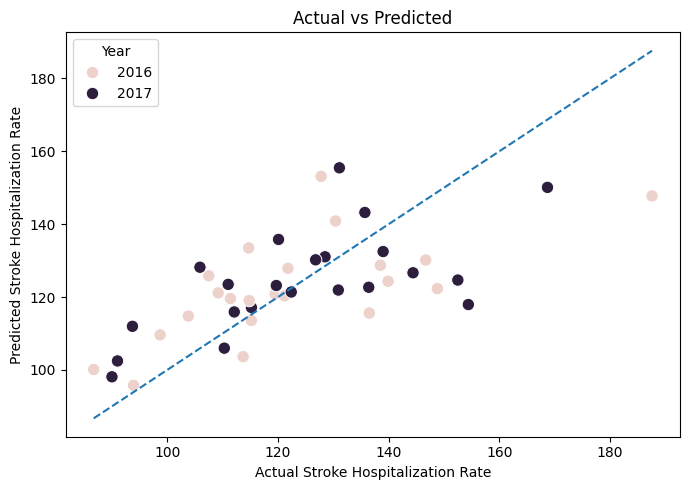

In [115]:
# Step 15. Actual vs Predicted plot

plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df_model,
    x=target,
    y="predicted_model_2",
    hue="Year",
    s=80
)
plt.plot(
    [df_model[target].min(), df_model[target].max()],
    [df_model[target].min(), df_model[target].max()],
    linestyle="--"
)
plt.xlabel("Actual Stroke Hospitalization Rate")
plt.ylabel("Predicted Stroke Hospitalization Rate")
plt.title("Actual vs Predicted")
plt.tight_layout()
plt.savefig(OUTPUTS / "actual_vs_predicted_model2.png")
plt.show()

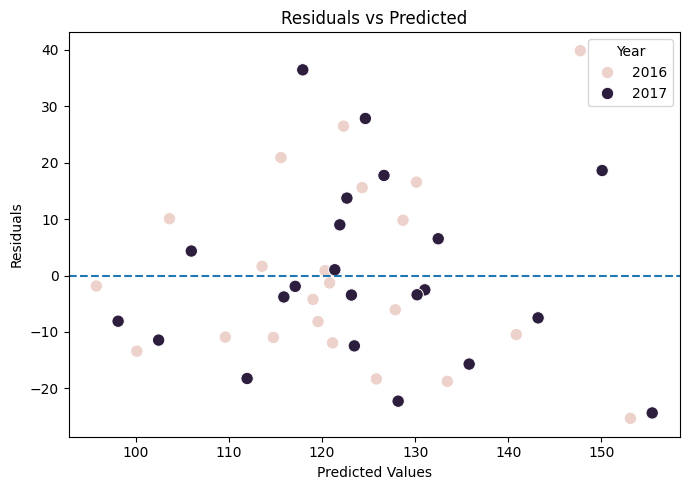

In [116]:
# Step 16. Residuals vs predicted

plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df_model,
    x="predicted_model_2",
    y="residuals_model_2",
    hue="Year",
    s=80
)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted")
plt.tight_layout()
plt.savefig(OUTPUTS / "residuals_vs_predicted_model2.png")
plt.show()

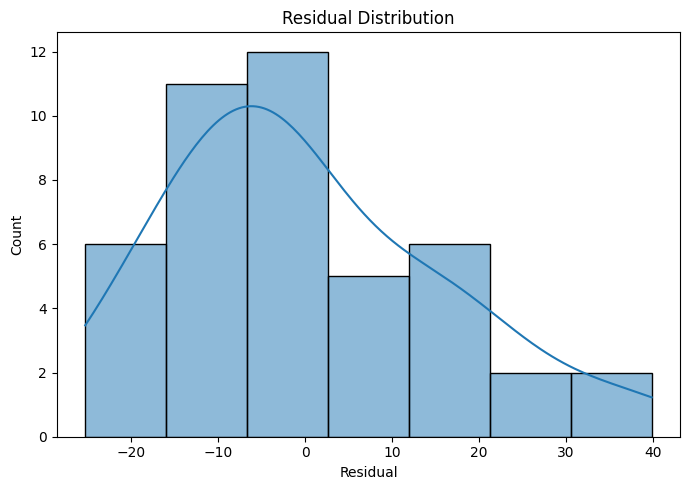

In [117]:
# Step 17. Residual histogram

plt.figure(figsize=(7, 5))
sns.histplot(df_model["residuals_model_2"], kde=True)
plt.title("Residual Distribution")
plt.xlabel("Residual")
plt.tight_layout()
plt.savefig(OUTPUTS / "residual_distribution_model2.png")
plt.show()

<Figure size 700x500 with 0 Axes>

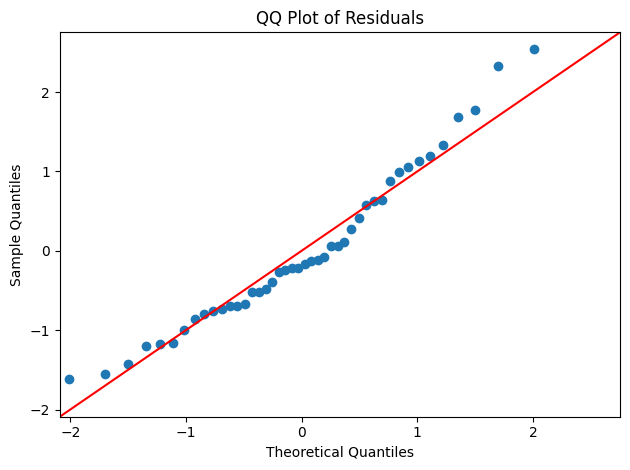

In [118]:
# Step 18. QQ Plot

plt.figure(figsize=(7, 5))
sm.qqplot(df_model["residuals_model_2"], line="45", fit=True)
plt.title("QQ Plot of Residuals")
plt.tight_layout()
plt.savefig(OUTPUTS / "qqplot_residuals_model2.png")
plt.show()

In [119]:
# Step 19. Standardized coefficient model

df_std = df_model.copy()

for col in [target] + risk_cols:
    df_std[col] = (df_std[col] - df_std[col].mean()) / df_std[col].std()

std_model = smf.ols(
    formula="""
    stroke_hosp_rate ~ smoking_rate + no_pa_minutes_rate + low_fv_rate + heavy_drinking_rate + C(Year)
    """,
    data=df_std
).fit()

std_coef_table = pd.DataFrame({
    "variable": std_model.params.index,
    "standardized_coefficient": std_model.params.values,
    "p_value": std_model.pvalues.values
})

std_coef_table

,variable,standardized_coefficient,p_value
0,Intercept,-0.055520,0.746453
1,C(Year)[T.2017],0.111041,0.647724
2,smoking_rate,0.725646,0.002435
3,no_pa_minutes_rate,-0.256678,0.086199
4,low_fv_rate,0.054159,0.713532
5,heavy_drinking_rate,-0.259806,0.249194


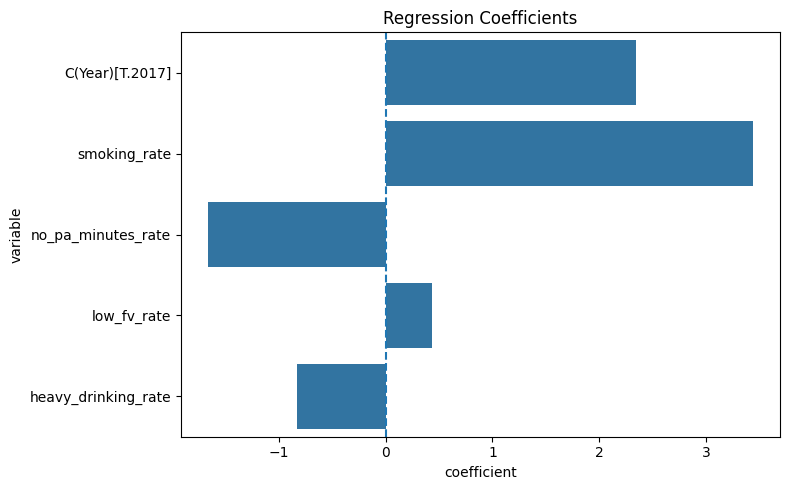

In [120]:
# Step 20. Coefficient plot

plot_df = coef_table[~coef_table["variable"].isin(["Intercept"])].copy()

plt.figure(figsize=(8, 5))
sns.barplot(data=plot_df, x="coefficient", y="variable")
plt.axvline(0, linestyle="--")
plt.title("Regression Coefficients")
plt.tight_layout()
plt.savefig(OUTPUTS / "regression_coefficients.png")
plt.show()

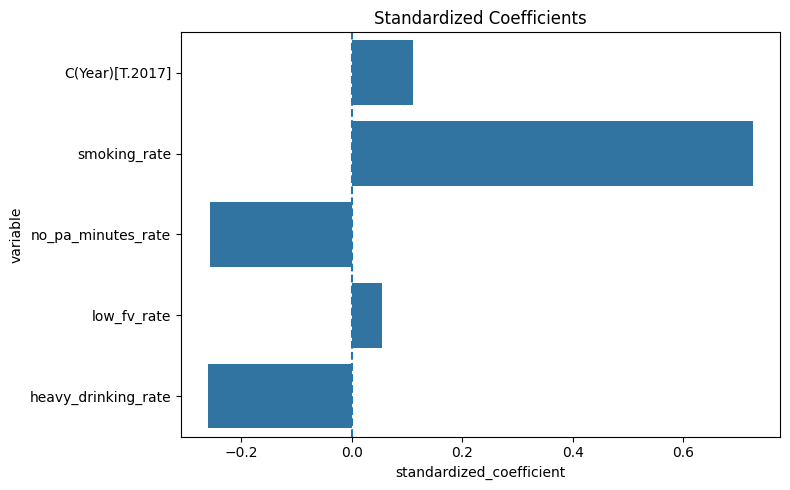

In [121]:
# Step 21. Standardized coefficient plot 

std_plot_df = std_coef_table[~std_coef_table["variable"].isin(["Intercept"])].copy()

plt.figure(figsize=(8, 5))
sns.barplot(data=std_plot_df, x="standardized_coefficient", y="variable")
plt.axvline(0, linestyle="--")
plt.title("Standardized Coefficients")
plt.tight_layout()
plt.savefig(OUTPUTS / "standardized_coefficients.png")
plt.show()

In [122]:
# Step 22. Prepare data for Ridge and Lasso

X_ml = df_model[risk_cols + ["Year"]].copy()
y_ml = df_model[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X_ml, y_ml, test_size=0.25, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (33, 5)
Test shape: (11, 5)


In [123]:
# Step 23. Ridge Regression

ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)

ridge_pred = ridge_model.predict(X_test_scaled)

ridge_results = {
    "Model": "Ridge",
    "R_squared": r2_score(y_test, ridge_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, ridge_pred)),
    "MAE": mean_absolute_error(y_test, ridge_pred)
}

ridge_results

{'Model': 'Ridge',
 'R_squared': 0.41634033682356353,
 'RMSE': np.float64(11.895524786232967),
 'MAE': 10.664397460295563}

In [124]:
# Step 24. Lasso Regression

lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_train_scaled, y_train)

lasso_pred = lasso_model.predict(X_test_scaled)

lasso_results = {
    "Model": "Lasso",
    "R_squared": r2_score(y_test, lasso_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, lasso_pred)),
    "MAE": mean_absolute_error(y_test, lasso_pred)
}

lasso_results

{'Model': 'Lasso',
 'R_squared': 0.431079903837958,
 'RMSE': np.float64(11.744361307184837),
 'MAE': 10.611163541797263}

In [125]:
# Step 25. Ridge and Lasso coefficients

ridge_coef_df = pd.DataFrame({
    "variable": X_ml.columns,
    "ridge_coefficient": ridge_model.coef_
})

lasso_coef_df = pd.DataFrame({
    "variable": X_ml.columns,
    "lasso_coefficient": lasso_model.coef_
})

ridge_coef_df, lasso_coef_df

(              variable  ridge_coefficient
 0         smoking_rate          11.043575
 1   no_pa_minutes_rate          -3.924649
 2          low_fv_rate           1.788714
 3  heavy_drinking_rate           0.381274
 4                 Year           0.650078,
               variable  lasso_coefficient
 0         smoking_rate          11.705552
 1   no_pa_minutes_rate          -3.882812
 2          low_fv_rate           1.488562
 3  heavy_drinking_rate          -0.000000
 4                 Year           0.637802)

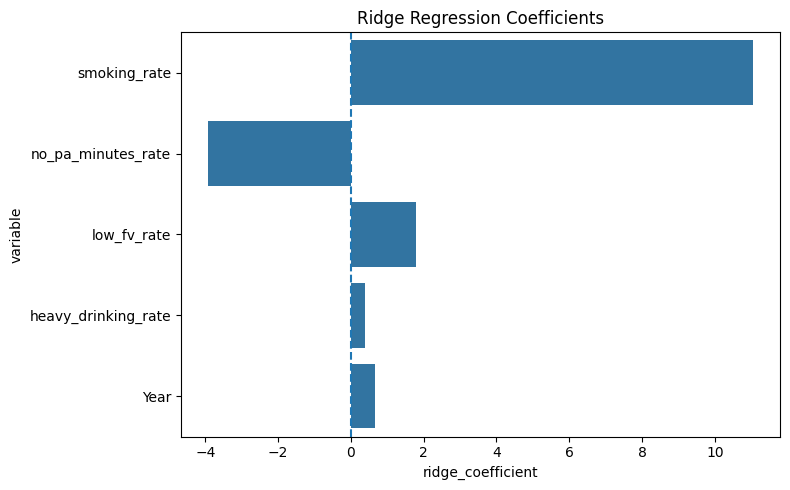

In [126]:
# Step 26. Plot Ridge Coefficients

plt.figure(figsize=(8, 5))
sns.barplot(data=ridge_coef_df, x="ridge_coefficient", y="variable")
plt.axvline(0, linestyle="--")
plt.title("Ridge Regression Coefficients")
plt.tight_layout()
plt.savefig(OUTPUTS / "ridge_coefficients.png")
plt.show()

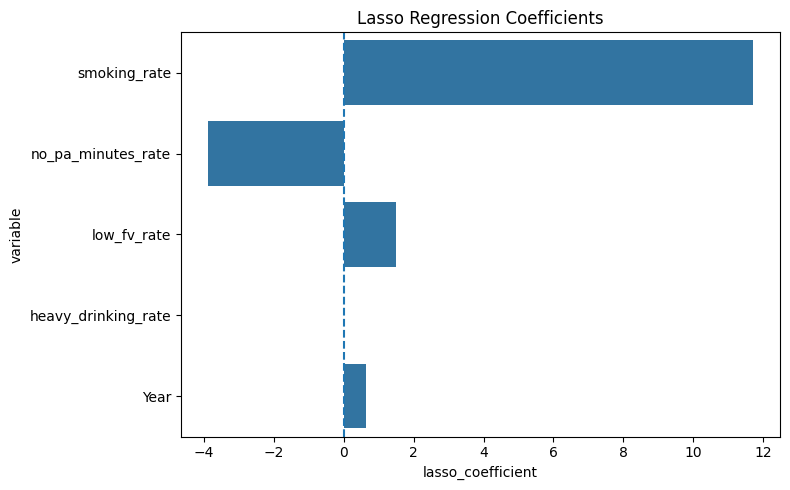

In [127]:
# Step 27. Plot Lasso Coefficients

plt.figure(figsize=(8, 5))
sns.barplot(data=lasso_coef_df, x="lasso_coefficient", y="variable")
plt.axvline(0, linestyle="--")
plt.title("Lasso Regression Coefficients")
plt.tight_layout()
plt.savefig(OUTPUTS / "lasso_coefficients.png")
plt.show()

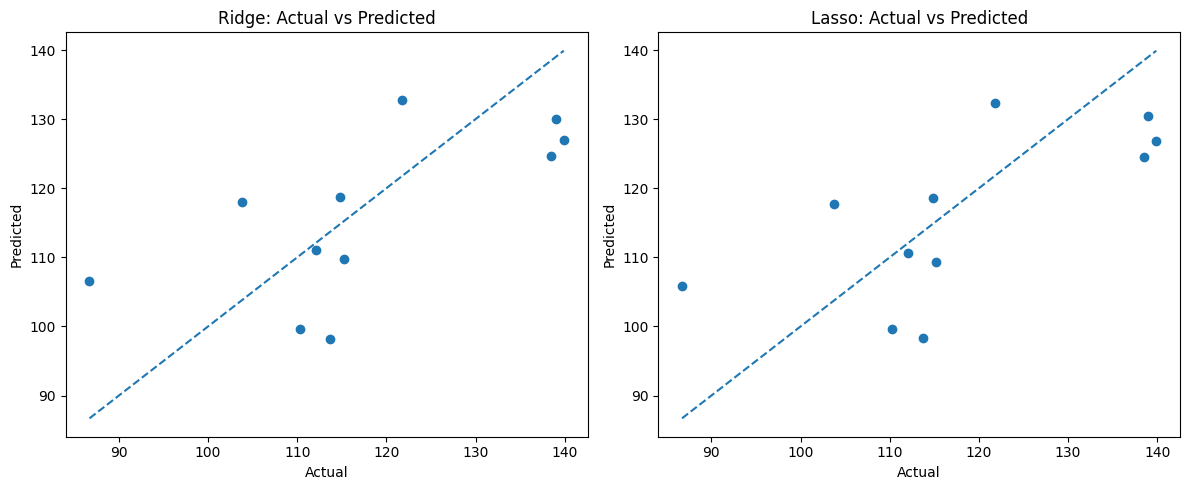

In [128]:
# Step 28. Actual vs predicted for Ridge and Lasso

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, ridge_pred)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], linestyle="--")
axes[0].set_title("Ridge: Actual vs Predicted")
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted")

axes[1].scatter(y_test, lasso_pred)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], linestyle="--")
axes[1].set_title("Lasso: Actual vs Predicted")
axes[1].set_xlabel("Actual")
axes[1].set_ylabel("Predicted")

plt.tight_layout()
plt.savefig(OUTPUTS / "ridge_lasso_actual_vs_predicted.png")
plt.show()

In [129]:
# Step 29. Compare all Models

ml_compare = pd.DataFrame([
    ridge_results,
    lasso_results
])

ols_compare = model_compare_ols.copy()
ols_compare

,Model,R_squared,Adj_R_squared,AIC,BIC
0,Baseline OLS,0.431830,0.373557,377.239191,386.160139
1,OLS + Year Effect,0.434985,0.360640,378.994243,389.699381


In [130]:
# Step 30. Save all Outputs

model_compare_ols.to_csv(DATA_PROCESSED / "model_compare_ols.csv", index=False)
vif_df.to_csv(DATA_PROCESSED / "model_vif.csv", index=False)
coef_table.to_csv(DATA_PROCESSED / "model_2_coefficients.csv", index=False)
std_coef_table.to_csv(DATA_PROCESSED / "model_2_standardized_coefficients.csv", index=False)
ridge_coef_df.to_csv(DATA_PROCESSED / "ridge_coefficients.csv", index=False)
lasso_coef_df.to_csv(DATA_PROCESSED / "lasso_coefficients.csv", index=False)
ml_compare.to_csv(DATA_PROCESSED / "ridge_lasso_metrics.csv", index=False)

with open(OUTPUTS / "model_1_summary.txt", "w") as f:
    f.write(model_1.summary().as_text())

with open(OUTPUTS / "model_2_summary.txt", "w") as f:
    f.write(model_2.summary().as_text())

with open(OUTPUTS / "model_2_robust_summary.txt", "w") as f:
    f.write(model_2_robust.summary().as_text())

print("All model outputs saved.")

All model outputs saved.


In [131]:
# Step 31. Final Interpretation helper

print("OLS model comparison")
print(model_compare_ols)

print("\nVIF")
print(vif_df)

print("\nModel 2 significant variables at p < 0.05")
print(coef_table[coef_table["p_value"] < 0.05][["variable", "coefficient", "p_value"]])

print("\nRidge metrics")
print(ridge_results)

print("\nLasso metrics")
print(lasso_results)

OLS model comparison
               Model  R_squared  Adj_R_squared         AIC         BIC
0       Baseline OLS   0.431830       0.373557  377.239191  386.160139
1  OLS + Year Effect   0.434985       0.360640  378.994243  389.699381

VIF
              variable          VIF
0                const  1247.605304
1         smoking_rate     3.357781
2   no_pa_minutes_rate     1.428031
3          low_fv_rate     1.441991
4  heavy_drinking_rate     3.314954

Model 2 significant variables at p < 0.05
       variable  coefficient   p_value
2  smoking_rate     3.437963  0.002435

Ridge metrics
{'Model': 'Ridge', 'R_squared': 0.41634033682356353, 'RMSE': np.float64(11.895524786232967), 'MAE': 10.664397460295563}

Lasso metrics
{'Model': 'Lasso', 'R_squared': 0.431079903837958, 'RMSE': np.float64(11.744361307184837), 'MAE': 10.611163541797263}


In [133]:
# Step 32. Optional PHU fixed effects model

model_3 = smf.ols(
    formula="""
    stroke_hosp_rate ~ smoking_rate + no_pa_minutes_rate + low_fv_rate + heavy_drinking_rate + C(Year) + C(PHU)
    """,
    data=df_model
).fit()

print(model_3.summary())

                            OLS Regression Results                            
Dep. Variable:       stroke_hosp_rate   R-squared:                       0.955
Model:                            OLS   Adj. R-squared:                  0.907
Method:                 Least Squares   F-statistic:                     20.16
Date:                Fri, 13 Mar 2026   Prob (F-statistic):           1.28e-09
Time:                        23:36:51   Log-Likelihood:                -127.94
No. Observations:                  44   AIC:                             301.9
Df Residuals:                      21   BIC:                             342.9
Df Model:                          22                                         
Covariance Type:            nonrobust                                         
                                                           coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------